# CASALS to 3DEP: physical vertical transformation and closure

## 1. Objective and reference systems

Convert CASALS ellipsoidal coordinates toward the documented NAVD88 target and assess closure using independent 3DEP evaluation. No parameter is estimated from CASALS-minus-3DEP residuals. Historical results and the [preserved audit](elevation_reference_audit.ipynb) remain unchanged.

| Item | CASALS source | Required 3DEP target | Evidence status |
|---|---|---|---|
| Height | WGS84 ellipsoidal Refh | NAVD88 orthometric height | Meeting convention / audited 3DEP metadata |
| Geoid | EGM2008 tide-free provided in L1B | GEOID18 | Official model identities |
| Realization | Specific WGS84 / ITRF / IGS realization unknown | NAD83(2011), GRS80 | Source unverified |
| Coordinate epoch | Unknown | 2010.0 for GEOID18 input | No verified source-to-target propagation |
| Additional corrections | Per-field sign and applied state unresolved | Traceable physical chain required | None additionally applied |

Sources: [2026-10-15 meeting](../../../docs/meeting/20261015_140029.txt), [3DEP provenance audit](../../../docs/casals_l1b_validation_report.md), [NOAA GEOID18 requirements](https://geodesy.noaa.gov/GEOID/GEOID18/geoid18_tech_details.shtml). The Maryland generic XML geoid conflict remains documented; final product evidence supports GEOID18 for both audited references.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import sys
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
while not (ROOT / 'pyproject.toml').is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'casals_l1b').is_dir()
sys.path.insert(0, str(ROOT))
from research.reference.vertical_alignment import run_alignment, plot_results
RUN_DIR = ROOT / 'outputs/notebooks/geolocation/vertical_datum_alignment/runs' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
R = run_alignment(RUN_DIR)
print('New output:', RUN_DIR.relative_to(ROOT))

[nptdms.tdms_segment WARNING] Data size 17582522368 is not a multiple of the chunk size 1441792. Will attempt to read last chunk


Processing casals_l1b_20241112T165718_001_02: physical heights, then class-2 reference


C:\Users\zhong267\AppData\Local\miniconda3\envs\map\Lib\site-packages\pyproj\transformer.py:207: UserWarning: Best transformation is not available due to missing Grid(short_name=us_noaa_g1999u08.tif, full_name=, package_name=, url=https://cdn.proj.org/us_noaa_g1999u08.tif, direct_download=True, open_license=True, available=False)
  super().__init__(


C:\Users\zhong267\AppData\Local\miniconda3\envs\map\Lib\site-packages\pyproj\transformer.py:207: UserWarning: Best transformation is not available due to missing Grid(short_name=us_noaa_g1999u08.tif, full_name=, package_name=, url=https://cdn.proj.org/us_noaa_g1999u08.tif, direct_download=True, open_license=True, available=False)
  super().__init__(


Processing casals_l1b_20241118T171757_001_02: physical heights, then class-2 reference


C:\Users\zhong267\AppData\Local\miniconda3\envs\map\Lib\site-packages\pyproj\transformer.py:207: UserWarning: Best transformation is not available due to missing Grid(short_name=us_noaa_g1999u08.tif, full_name=, package_name=, url=https://cdn.proj.org/us_noaa_g1999u08.tif, direct_download=True, open_license=True, available=False)
  super().__init__(


C:\Users\zhong267\AppData\Local\miniconda3\envs\map\Lib\site-packages\pyproj\transformer.py:207: UserWarning: Best transformation is not available due to missing Grid(short_name=us_noaa_g1999u08.tif, full_name=, package_name=, url=https://cdn.proj.org/us_noaa_g1999u08.tif, direct_download=True, open_license=True, available=False)
  super().__init__(


New output: outputs\notebooks\geolocation\vertical_datum_alignment\runs\20261015T214817464342Z


## 2. Source height and correction audit

The current H5 root attributes, all twelve scalar fields below, and metadata from both local TDMS files are reread. Every correction's complete definition, units, affected physical quantity, sign, applied state, expected effect, and current action are recorded in `physical_correction_audit.csv`. The tables distinguish the confirmed input/model from unresolved processing contracts.

`casals_epoch_*` and `delta_time` define observation-time bookkeeping from 2018-01-01; this is not a navigation coordinate epoch. H5 references GPS CSV, geolocation, L1A/ARD and TDMS files whose exact basenames are absent locally. The available TDMS files contain timing/scan properties and no navigation realization or epoch, and do not match the H5 upstream basenames. The [NASA system paper](https://ntrs.nasa.gov/api/citations/20240001267/downloads/Conference%20Paper.pdf) identifies POS 510 hardware, not the frame or processing state of these granules.

Neutral atmospheric optical path, one-/two-way travel time, slant range, and vertical height are different quantities. For a confirmed omitted positive excess range, the first-order height effect would be `delta_h = -delta_range * dot(beam_sensor_to_target, local_up)`. Its use would require a confirmed range equation, units, beam convention, sign, and unapplied status. Those conditions are not established; the stored 1-1.6 numeric delay is not applied. Zero range bias is not proof of an applied zero calibration. Tide terms are not summed or sign-tested as formal transformations.

In [2]:
audit = R['corrections']
display(audit.drop_duplicates('field')[['field', 'official_definition', 'units', 'acts_on',
    'sign_convention', 'applied_to_refh', 'current_action']].reset_index(drop=True))
display(Markdown('**Current full-granule numeric medians (undeclared H5 units remain undeclared)**'))
display(audit.pivot(index='field', columns='granule_id', values='median_numeric').round(6))
assert not audit.eligible_for_additional_correction.any()

,field,official_definition,units,acts_on,sign_convention,applied_to_refh,current_action
0,refh,WGS84 ellipsoidal reference-return height (mee...,m (product convention; H5 undeclared),ellipsoidal height,UNKNOWN,input; not an extra correction,input height
1,geoid,"EGM2008 tide-free geoid height (Jeff Lee, meet...",m (NGA numerical validation),geoid height,H_EGM = h - N_EGM,UNKNOWN,EGM2008 diagnostic only
2,geoid_free2mean,Mean-tide geoid conversion provided (meeting);...,UNKNOWN,geoid height; complete height chain unknown,UNKNOWN,UNKNOWN,not applied
3,refh_neutat_delay_total,UNKNOWN: no per-field official processing cont...,UNKNOWN,neutral atmosphere optical path/range/time: ex...,UNKNOWN,UNKNOWN,not applied
4,refh_neutat_delay_derivative,UNKNOWN: no per-field official processing cont...,UNKNOWN,delay derivative; independent/dependent units ...,UNKNOWN,UNKNOWN,not applied
5,range_bias_correction,UNKNOWN: no per-field official processing cont...,UNKNOWN,range (field name only; official definition un...,UNKNOWN,UNKNOWN,not applied
6,tide_earth,UNKNOWN: no per-field official processing cont...,UNKNOWN,solid-Earth/load/ocean/pole/permanent-tide ter...,UNKNOWN,UNKNOWN,not applied
7,tide_earth_free2mean,UNKNOWN: no per-field official processing cont...,UNKNOWN,solid-Earth/load/ocean/pole/permanent-tide ter...,UNKNOWN,UNKNOWN,not applied
8,tide_load,UNKNOWN: no per-field official processing cont...,UNKNOWN,solid-Earth/load/ocean/pole/permanent-tide ter...,UNKNOWN,UNKNOWN,not applied
9,tide_ocean,UNKNOWN: no per-field official processing cont...,UNKNOWN,solid-Earth/load/ocean/pole/permanent-tide ter...,UNKNOWN,UNKNOWN,not applied


**Current full-granule numeric medians (undeclared H5 units remain undeclared)**

granule_id,casals_l1b_20241112T165718_001_02,casals_l1b_20241118T171757_001_02
field,,
geoid,-36.832462,-37.431847
geoid_free2mean,-0.019859,-0.005459
range_bias_correction,0.000000,0.000000
refh,-25.504444,-32.380623
refh_neutat_delay_derivative,0.000278,0.000278
refh_neutat_delay_total,1.593985,1.180952
tide_earth,-0.015728,-0.075044
tide_earth_free2mean,-0.009538,-0.002770
tide_load,0.006266,0.001652


## 3. Reference-frame transformation

The actual operation is audited, including its parameters and separate longitude, latitude, and ellipsoidal-height changes. A non-ballpark API result can still be a null frame transformation. Here the WGS84 ensemble to NAD83(2011) step is `proj=noop ellps=GRS80`, with three zero translations and 2 m stated accuracy. It does not identify a specific source realization, propagate coordinates to 2010.0, or establish a physical 3D frame solution.

[NGS HTDP User Guide](https://geodesy.noaa.gov/TOOLS/Htdp/HTDP-user-guide.pdf), sections 8-9 and Tables 4-5: time-dependent transformations require identified frames and epochs; WGS84 transformations are approximate. HTDP cannot transform between realizations within one NAD83 plate frame; NGS points to NCAT for that task. No HTDP or Helmert correction is run because CASALS source realization and coordinate epoch remain unidentified. Flight date alone does not establish either input condition.

In [3]:
frame_columns = ['granule_id', 'source_frame', 'source_realization', 'source_coordinate_epoch',
    'target_frame', 'required_target_coordinate_epoch', 'target_coordinate_epoch_achieved',
    'is_noop', 'is_ballpark', 'accuracy_metadata_m', 'delta_longitude_deg_max_abs',
    'delta_latitude_deg_max_abs', 'delta_ellipsoidal_height_m_median', 'delta_ellipsoidal_height_m_max_abs']
display(R['frame'][frame_columns])
for gid, op in R['operations']['granules'].items():
    display(Markdown('**' + gid + ': actual combined operation**' + chr(10) + '```text' + chr(10) + op['combined_operation'] + chr(10) + '```'))
samples = R['population'].groupby('granule_id', sort=True).head(1)
display(samples[['granule_id', 'pulse_index', 'longitude_deg', 'latitude_deg', 'Native_height_m',
    'frame_longitude_deg', 'frame_latitude_deg', 'frame_ellipsoidal_height_m',
    'frame_delta_longitude_deg', 'frame_delta_latitude_deg', 'frame_delta_ellipsoidal_height_m']])

,granule_id,source_frame,source_realization,source_coordinate_epoch,target_frame,required_target_coordinate_epoch,target_coordinate_epoch_achieved,is_noop,is_ballpark,accuracy_metadata_m,delta_longitude_deg_max_abs,delta_latitude_deg_max_abs,delta_ellipsoidal_height_m_median,delta_ellipsoidal_height_m_max_abs
0,casals_l1b_20241112T165718_001_02,WGS84 ensemble (EPSG:4979),None,None,NAD83(2011) (EPSG:6319),2010.0,None,True,False,2.0,0.0,0.0,0.0,0.0
1,casals_l1b_20241118T171757_001_02,WGS84 ensemble (EPSG:4979),None,None,NAD83(2011) (EPSG:6319),2010.0,None,True,False,2.0,0.0,0.0,0.0,0.0


**casals_l1b_20241112T165718_001_02: actual combined operation**
```text
proj=pipeline step proj=unitconvert xy_in=deg xy_out=rad step inv proj=vgridshift grids=us_noaa_g2018u0.tif multiplier=1 step proj=utm zone=18 ellps=GRS80
```

**casals_l1b_20241118T171757_001_02: actual combined operation**
```text
proj=pipeline step proj=unitconvert xy_in=deg xy_out=rad step inv proj=vgridshift grids=us_noaa_g2018u0.tif multiplier=1 step proj=utm zone=18 ellps=GRS80
```

,granule_id,pulse_index,longitude_deg,latitude_deg,Native_height_m,frame_longitude_deg,frame_latitude_deg,frame_ellipsoidal_height_m,frame_delta_longitude_deg,frame_delta_latitude_deg,frame_delta_ellipsoidal_height_m
0,casals_l1b_20241112T165718_001_02,1040402,-75.281099,38.410052,-166.092717,-75.281099,38.410052,-166.092717,0.0,0.0,0.0
36276,casals_l1b_20241118T171757_001_02,2821855,-76.695553,36.189333,-33.406726,-76.695553,36.189333,-33.406726,0.0,0.0,0.0


## 4. Physical vertical transformation

The only computed methods are:

| Method | Calculation | Meaning |
|---|---|---|
| Native | `refh` | Original ellipsoidal reference-return height |
| EGM2008 | `refh - geoid` | Meeting-confirmed EGM2008-referenced height; not NAVD88 |
| GEOID18 | Existing C7 XYZ operation | **Provisional physical transformation**, because its source-frame step is unresolved |

The strict target equation is `H_NAVD88 = h_NAD83(2011),2010.0 - N_GEOID18`. The C7 implementation reproduces that vertical grid operation under its source-frame assumption; the equation's frame/epoch premise has not been verified for CASALS. No EGM2008-minus-GEOID18 difference is used as a correction.

The audited `us_noaa_g2018u0.tif` is reused with SHA-256 `fa9a407ac7ee3f5a3694008e4bcd09ce9cc250452f0c3b11700a4960340abce2`. Its grid CRS is EPSG:6319, target EPSG:5703, area CONUS. A separate four-cell raster interpolation checks one real source point per granule without using PROJ to sample N: the signed undulation is subtracted. These are numerical direction/height checks, not verification of the assumed source frame.

In [4]:
point_rows = []
for gid, op in R['operations']['granules'].items():
    point_rows.append({'granule_id': gid, **op['independent_grid_point'],
        'median_total_vertical_change_m': op['median_total_vertical_change_m']})
display(pd.DataFrame(point_rows)[['granule_id', 'longitude_deg', 'latitude_deg',
    'assumed_NAD83_ellipsoidal_h_m', 'N_GEOID18_m', 'independently_computed_H_m',
    'PROJ_H_m', 'difference_m', 'median_total_vertical_change_m']].round(8))
display(Markdown('**EGM2008 historical numeric consistency (1,200 unchanged coordinates per granule)**'))
display(R['geoid'].round(8))
display(Markdown('**C7 height, reference-plane and pulse-set parity**'))
display(R['parity'].round(12))

,granule_id,longitude_deg,latitude_deg,assumed_NAD83_ellipsoidal_h_m,N_GEOID18_m,independently_computed_H_m,PROJ_H_m,difference_m,median_total_vertical_change_m
0,casals_l1b_20241112T165718_001_02,-75.281099,38.410052,-166.092717,-35.902558,-130.190159,-130.190159,0.0,35.898677
1,casals_l1b_20241118T171757_001_02,-76.695553,36.189333,-33.406726,-36.385140,2.978414,2.978414,-0.0,36.368041


**EGM2008 historical numeric consistency (1,200 unchanged coordinates per granule)**

,granule_id,n,H5_minus_NGA_EGM2008_median_m,max_abs_m
0,casals_l1b_20241112T165718_001_02,1200,0.000438,0.000984
1,casals_l1b_20241118T171757_001_02,1200,-0.002074,0.002750


**C7 height, reference-plane and pulse-set parity**

,granule_id,population,n,pulse_sha256,max_height_difference_m,max_reference_difference_m
0,casals_l1b_20241112T165718_001_02,field,32859,92e256f3e8eb312b13ef1db5766c8935f721789bc24e75...,0.0,0.0
1,casals_l1b_20241112T165718_001_02,road,147,061792665502668adf77da09a6371f3bc8cd17d3e4e2d9...,0.0,0.0
2,casals_l1b_20241118T171757_001_02,field,16064,42dd484170417cd1165062570145263e3f0994c9b47e4a...,0.0,0.0
3,casals_l1b_20241118T171757_001_02,road,165,e575da0e4d485c7f1a16545a2b0fc457a60f7086cd3a2c...,0.0,0.0


## 5. CASALS versus independent 3DEP

`residual = CASALS_transformed_height - 3DEP_height`, in metres. CASALS heights are calculated using only four H5 inputs plus official geodetic models. Only afterward are 3DEP class-2 reference surfaces queried and evaluation residuals calculated; reference values cannot feed back into heights.

The fixed historical field and road pulse sets are unchanged. Primary reporting uses supported, low-slope field test ROIs at SNR >= 5; SNR >= 3 and all-valid strata retain every tail. Legacy split labels are membership evidence only and do not trigger parameter estimation. Coverage denominator is all fixed test-ROI pulses in the stratum before reference support rejection. Field seasonal cover remains uncertain; SNR does not classify a return as ground. Reviewed road interiors are a separate conditional check.

The original 0.75 m class-2 grid, every-10,000th-record holdout, robust local plane, >=6 neighbors within 3 m, <=5 degree slope, and <=0.20 m plane-residual NMAD are reused. Every method uses exactly the same pulse IDs and recomputed C7 reference heights. The signed bias remains reported: `RMSE**2 = mean_bias**2 + centered_RMSE**2`; centered dispersion is not absolute accuracy. No CASALS residual is removed by magnitude.

In [5]:
metric_columns = ['granule_id', 'stratum', 'method', 'eligible_n', 'n', 'coverage',
    'mean_bias_m', 'median_bias_m', 'RMSE_m', 'cRMSE_m', 'NMAD_m', 'absolute_P95_m']
display(R['metrics'].query("population == 'field'")[metric_columns].round(4))
display(Markdown('**Reviewed road independent-test check; separate population**'))
display(R['metrics'].query("population == 'road'")[metric_columns].round(4))

,granule_id,stratum,method,eligible_n,n,coverage,mean_bias_m,median_bias_m,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m
0,casals_l1b_20241112T165718_001_02,all_valid_refh,Native,17171,14885,0.8669,-13.4546,-37.5635,81.8953,80.7826,0.2954,180.3539
1,casals_l1b_20241112T165718_001_02,all_valid_refh,EGM2008,17171,14885,0.8669,23.3833,-0.7257,84.0987,80.7825,0.2957,208.3507
2,casals_l1b_20241112T165718_001_02,all_valid_refh,GEOID18,17171,14885,0.8669,22.4477,-1.6613,83.8434,80.7825,0.2957,207.4152
3,casals_l1b_20241112T165718_001_02,snr_ge_3,Native,4852,4274,0.8809,-37.3889,-37.5820,38.3468,8.5174,0.1174,37.8136
4,casals_l1b_20241112T165718_001_02,snr_ge_3,EGM2008,4852,4274,0.8809,-0.5510,-0.7440,8.5352,8.5174,0.1173,0.9791
5,casals_l1b_20241112T165718_001_02,snr_ge_3,GEOID18,4852,4274,0.8809,-1.4866,-1.6796,8.6462,8.5174,0.1173,1.9147
6,casals_l1b_20241112T165718_001_02,snr_ge_5,Native,478,445,0.9310,-37.5729,-37.5633,37.5730,0.1005,0.0876,37.7529
7,casals_l1b_20241112T165718_001_02,snr_ge_5,EGM2008,478,445,0.9310,-0.7349,-0.7252,0.7417,0.1005,0.0877,0.9151
8,casals_l1b_20241112T165718_001_02,snr_ge_5,GEOID18,478,445,0.9310,-1.6705,-1.6609,1.6735,0.1005,0.0877,1.8507
18,casals_l1b_20241118T171757_001_02,all_valid_refh,Native,8924,8924,1.0000,-36.4329,-38.0194,41.1173,19.0599,0.0948,38.2131


**Reviewed road independent-test check; separate population**

,granule_id,stratum,method,eligible_n,n,coverage,mean_bias_m,median_bias_m,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m
9,casals_l1b_20241112T165718_001_02,all_valid_refh,Native,1131,147,0.1300,-4.9917,-37.6938,92.9330,92.7988,0.3181,186.4110
10,casals_l1b_20241112T165718_001_02,all_valid_refh,EGM2008,1131,147,0.1300,31.8425,-0.8595,98.1099,92.7988,0.3180,214.7503
11,casals_l1b_20241112T165718_001_02,all_valid_refh,GEOID18,1131,147,0.1300,30.9070,-1.7951,97.8103,92.7988,0.3180,213.8148
12,casals_l1b_20241112T165718_001_02,snr_ge_3,Native,453,54,0.1192,-36.1486,-37.7255,37.9431,11.5307,0.1265,37.9607
13,casals_l1b_20241112T165718_001_02,snr_ge_3,EGM2008,453,54,0.1192,0.6857,-0.8912,11.5510,11.5307,0.1265,1.1265
14,casals_l1b_20241112T165718_001_02,snr_ge_3,GEOID18,453,54,0.1192,-0.2499,-1.8268,11.5334,11.5307,0.1265,2.0620
15,casals_l1b_20241112T165718_001_02,snr_ge_5,Native,84,14,0.1667,-37.7221,-37.7364,37.7223,0.1014,0.0456,37.8482
16,casals_l1b_20241112T165718_001_02,snr_ge_5,EGM2008,84,14,0.1667,-0.8878,-0.9021,0.8936,0.1014,0.0456,1.0139
17,casals_l1b_20241112T165718_001_02,snr_ge_5,GEOID18,84,14,0.1667,-1.8234,-1.8377,1.8262,0.1014,0.0456,1.9494
27,casals_l1b_20241118T171757_001_02,all_valid_refh,Native,225,165,0.7333,-34.5253,-37.9497,40.1461,20.4868,0.1136,38.2345


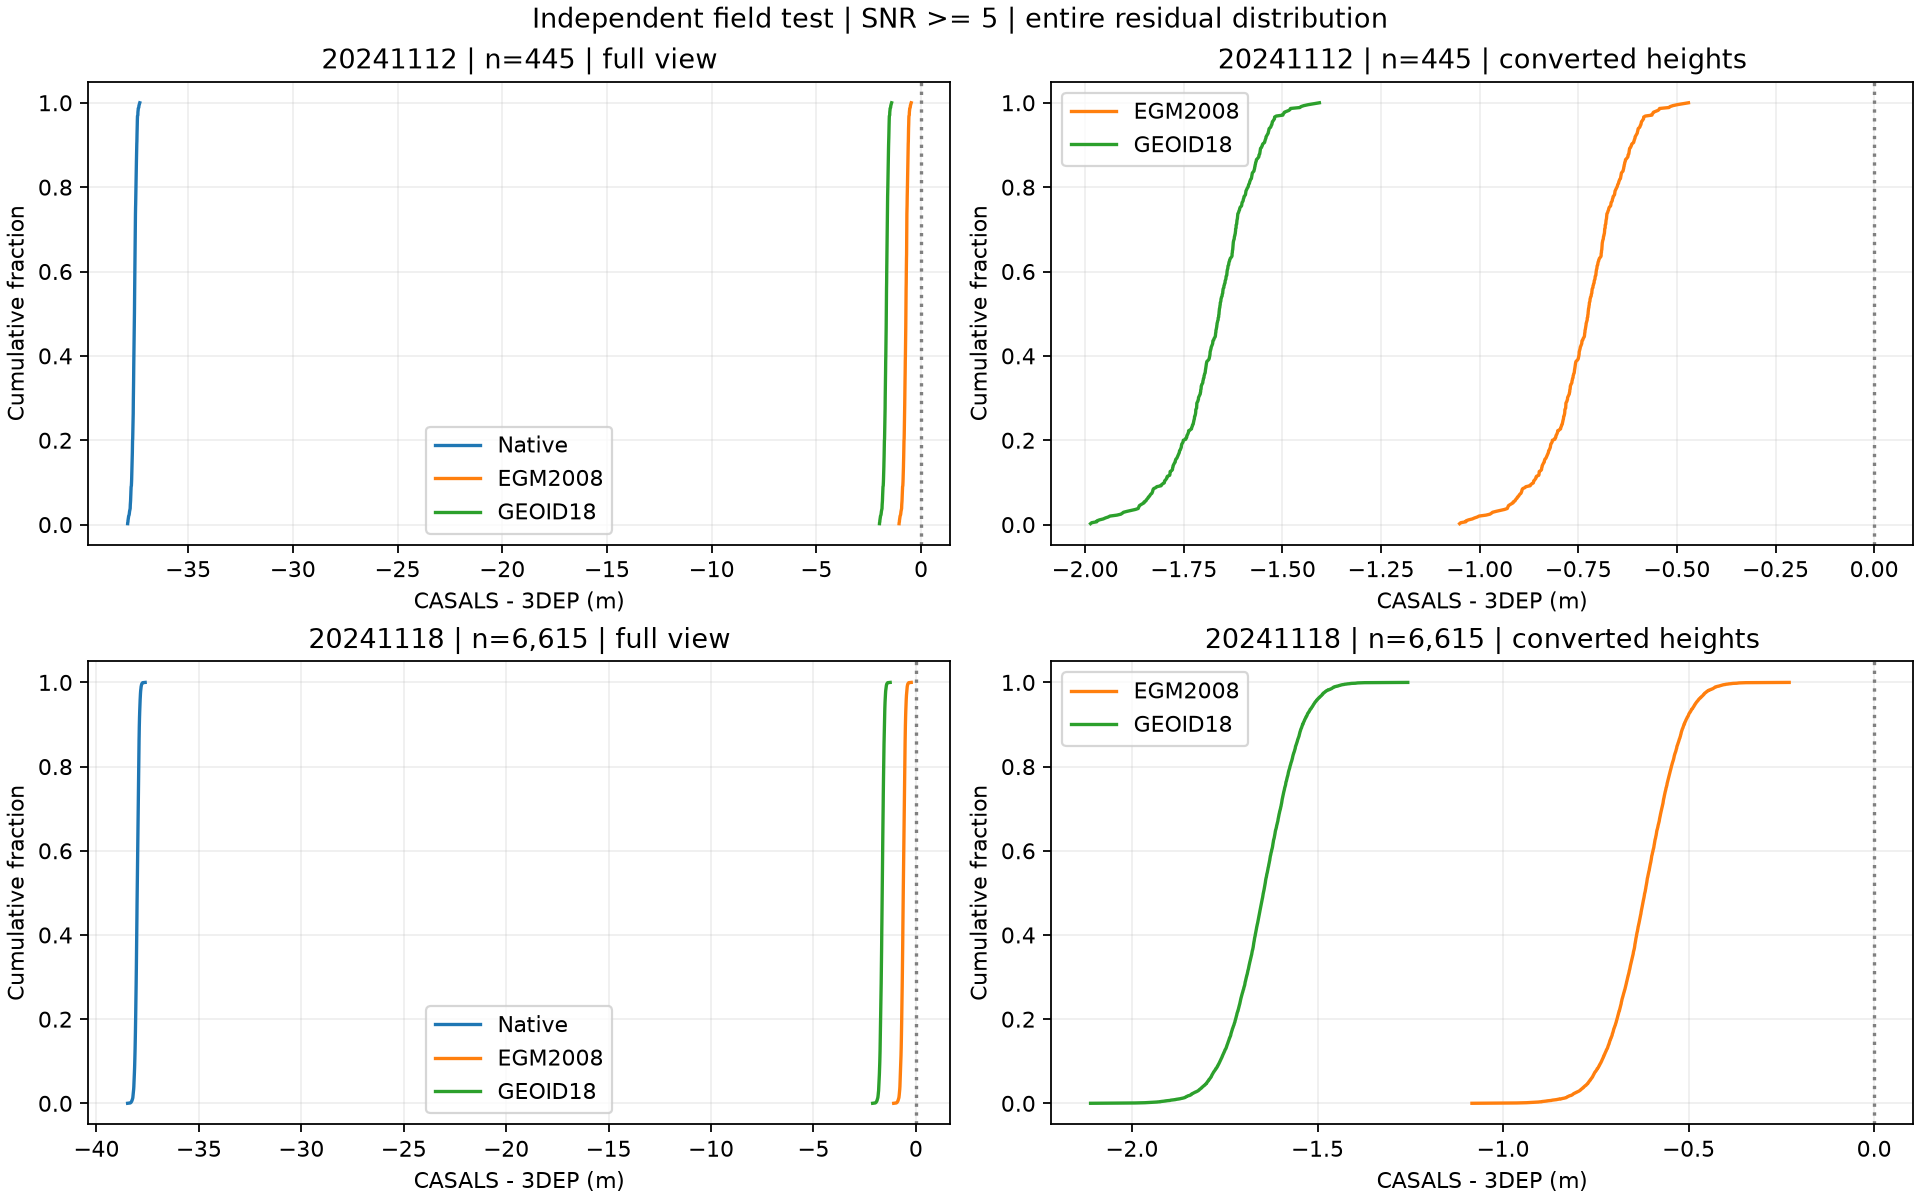

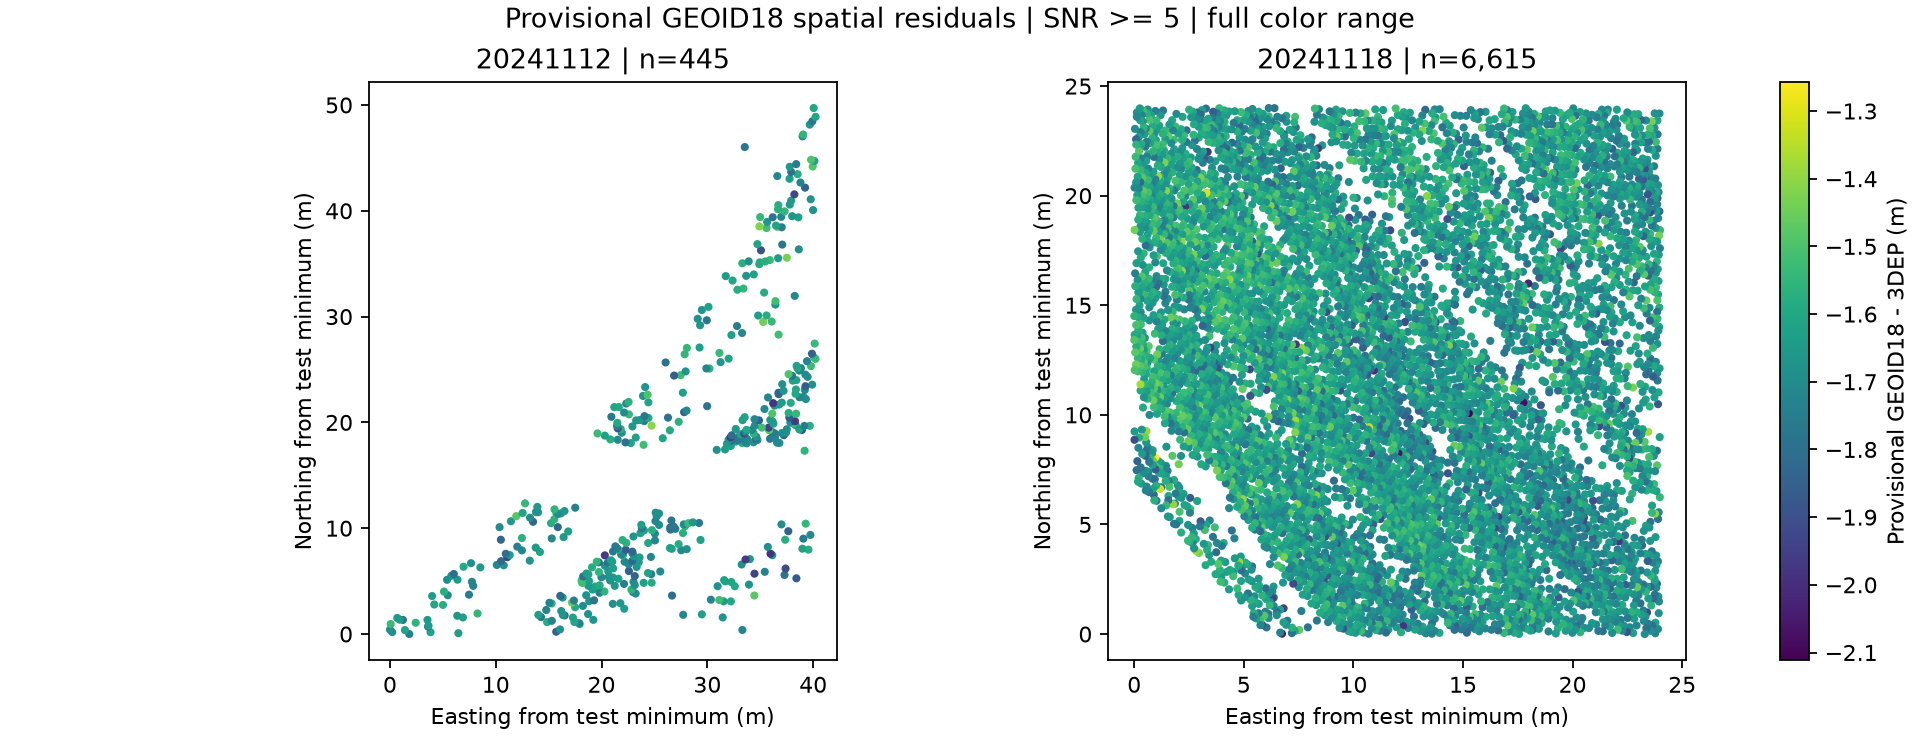

In [6]:
import matplotlib.pyplot as plt
for name, fig in plot_results(R):
    display(Image(filename=str(RUN_DIR / name)))
    plt.close(fig)

## 6. Closure assessment

**Strict physical transformation and height closure are not achieved.** No independently validated new physical correction was found. The numeric C7 grid transformation remains reproducible, while its no-op source-frame step and unverified coordinate epochs prevent a verified NAVD88 conversion claim. The unchanged negative residual bias is retained.

Required evidence is the per-granule GNSS/INS realization and coordinate epoch, any intermediate-frame transformations and epoch propagation, and the processor's exact Refh bin/time-to-range equation with field-level units, signs, application stages and applied/not-applied records. Atmospheric and other range/tide terms cannot be reapplied without that evidence. The final summary includes no residual-derived height correction or near-zero-bias result.

In [7]:
final_columns = ['granule_id', 'status', 'n', 'eligible_n', 'coverage', 'mean_bias_m',
    'median_bias_m', 'RMSE_m', 'cRMSE_m', 'NMAD_m', 'absolute_P95_m', 'strict_closure']
display(R['final_summary'][final_columns].round(4))
for row in R['final_summary'].itertuples():
    display(Markdown(f"**{row.granule_id[11:19]}:** provisional GEOID18, n={row.n:,}; signed bias {row.mean_bias_m:+.4f} m, RMSE {row.RMSE_m:.4f} m, centered RMSE {row.cRMSE_m:.4f} m, NMAD {row.NMAD_m:.4f} m. Strict closure: **not achieved**. No additional correction applied."))

,granule_id,status,n,eligible_n,coverage,mean_bias_m,median_bias_m,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m,strict_closure
8,casals_l1b_20241112T165718_001_02,provisional physical transformation,445,478,0.931,-1.6705,-1.6609,1.6735,0.1005,0.0877,1.8507,False
26,casals_l1b_20241118T171757_001_02,provisional physical transformation,6615,6615,1.000,-1.6486,-1.6456,1.6510,0.0892,0.0874,1.7972,False


**20241112:** provisional GEOID18, n=445; signed bias -1.6705 m, RMSE 1.6735 m, centered RMSE 0.1005 m, NMAD 0.0877 m. Strict closure: **not achieved**. No additional correction applied.

**20241118:** provisional GEOID18, n=6,615; signed bias -1.6486 m, RMSE 1.6510 m, centered RMSE 0.0892 m, NMAD 0.0874 m. Strict closure: **not achieved**. No additional correction applied.